# Model Training & Analysis

Trains the final LightGBM model using the tuned hyperparameters, evaluates it,
and registers it with MLflow.

**Pipeline overview**
1. Load `model_dataset.parquet` & tuned hyperparameters
2. Train / test split — the 20% test holdout matches Notebook 2's (same `RANDOM_STATE`/`TEST_SIZE`) and is used only for final evaluation
3. 5-fold cross-validation (number of trees, threshold), then the final model on the full training set
4. Find the optimal classification threshold (F1-maximizing, on out-of-fold predictions)
5. Compute & export evaluation metrics
6. Feature importance & interpretability (gain, SHAP, combined table)
7. ROC & Precision-Recall curves
8. MLflow tracking & model registration

**Outputs:**
- `data/Model-Training/ModelOutput/classification_report_optimal_threshold.{txt,csv}`
- `data/Model-Training/ModelOutput/lgbm_feature_importance.xlsx`
- `data/Model-Training/ModelOutput/model_evaluation_curves.png`
- MLflow run + registered model `HomeCredit_Scorecard_Model`

## 1. Imports & Configuration

In [ ]:
import os
import json
import pandas as pd
import numpy as np
import lightgbm as lgb
import shap
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (
    accuracy_score, roc_auc_score, log_loss,
    precision_score, recall_score, f1_score,
    precision_recall_curve, classification_report,
    roc_curve, auc,
)
PROJECT_ROOT = os.environ.get("HOMECREDIT_PROJECT_ROOT", r"a:\Dominic\My Projects\Home Credit")
DATA_ROOT = os.environ.get("HOMECREDIT_DATA_ROOT", r"a:\Dominic\My Projects\Home Credit\data")
SRC_ROOT  = os.environ.get("HOMECREDIT_SRC_DIR", r"a:\Dominic\My Projects\Home Credit\src")

MDS_DIR = os.path.join(DATA_ROOT, "Model-Training", "ModelDataset")
HPO_DIR = os.path.join(DATA_ROOT, "Model-Training", "HyperParameters")
VAR_SELECTION_DIR = os.path.join(DATA_ROOT, "Model-Training", "Variable-Selection")

PATH_MODEL_DATASET = os.path.join(MDS_DIR, "model_dataset_final.parquet")
PATH_BEST_HYPERPARS = os.path.join(HPO_DIR, "LightGBM_v4", "lgbm_resolved_best.json")  # from 04_Model-Development/LightGBM_v4
# Feature list written by the same tuning notebook
PATH_FEATURE_LIST = os.path.join(os.path.dirname(PATH_BEST_HYPERPARS), "selected_features.json")
PATH_SELECTED_FEATURES = os.path.join(VAR_SELECTION_DIR, "numeric_selection_metrics_full_df.xlsx")

MODEL_OUTPUT_DIR = os.path.join(DATA_ROOT, "Model-Training", "ModelOutput", "LightGBM_v4")
os.makedirs(MODEL_OUTPUT_DIR, exist_ok=True)

# ── MUST match Notebook 2 exactly — same split = comparable AUC/metrics ──────
RANDOM_STATE = 1994
TEST_SIZE    = 0.20
# Cross-validation folds on the 80% training set. They choose the two things the
# model can't learn from its own training data: the number of trees (early stopping
# in each fold) and the classification threshold (out-of-fold predictions). The final
# model is then trained on the full 80%; the TEST_SIZE holdout is never touched by
# training or tuning, so metrics reported on it are unbiased.
CV_FOLDS     = 5

# Upper bound on boosting rounds in the CV folds; early stopping picks the real number.
# Without it the model silently falls back to the library default of 100 trees.
N_ESTIMATORS_MAX = 5000

# ── Hyperparameters ──────────────────────────────────────────────────────────
#   'tuned'    -> the tuning notebook's saved resolved-best JSON (default)
#   'defaults' -> the library's built-in defaults: a baseline showing what tuning adds
# Set per run via the HOMECREDIT_HYPERPARAMS env var, or edit here. Under Airflow
# (05_model_pipeline) training always uses 'tuned'; 'defaults' is for manual baseline runs.
HYPERPARAMS_SOURCE = os.environ.get("HOMECREDIT_HYPERPARAMS", "tuned").strip().lower()
assert HYPERPARAMS_SOURCE in ("tuned", "defaults"), f"unknown HYPERPARAMS_SOURCE {HYPERPARAMS_SOURCE!r}"

# ── MLflow toggle ─────────────────────────────────────────────────────────
ENABLE_MLFLOW = True
# MLflow tracking server (docker-compose `mlflow` service): metadata lives in
# DATA_ROOT/mlflow.db and artifacts are uploaded through the server, so runs and
# registered models work from Windows and from Docker alike. Airflow's container
# sets MLFLOW_TRACKING_URI=http://mlflow:5000. Running locally on Windows, start the
# server first with `python scripts/start_mlflow_server.py` (or `docker compose up -d mlflow`).
MLFLOW_TRACKING_URI = os.environ.get("MLFLOW_TRACKING_URI", "http://localhost:5000")
MLFLOW_EXPERIMENT_NAME = "Home_Credit_Default_Risk"
MLFLOW_REGISTERED_MODEL_NAME = "HomeCredit_Scorecard_Model"
# Derived from MODEL_OUTPUT_DIR ("LightGBM_v4") -- used as the run name and a
# "model_name" tag so this model version is distinguishable from other
# LightGBM_vN runs in the MLflow UI (Runs table, and the Chart tab's legend/axis).
MLFLOW_RUN_NAME = os.path.basename(MODEL_OUTPUT_DIR)

## 2. Load Data & Tuned Hyperparameters

> **Features:** read from this version's tuning notebook (`selected_features.json`
> next to its hyperparameters), so tuning and training always use the same list. The
> selection rule lives in the tuning notebook — run it first, and again whenever the
> features should change.

> **Fixed test set:** every tuning and training notebook, for every model version,
> uses this exact split (`RANDOM_STATE = 1994`, `TEST_SIZE = 0.20`, stratified on
> `TARGET`), so all versions are graded on the same 61,503 test applicants and their
> test metrics are directly comparable. The test set is the final exam: nothing —
> hyperparameters, number of trees, threshold, or the next version's features — may
> be chosen using it.

In [ ]:
model_dataset = pd.read_parquet(PATH_MODEL_DATASET)

# Features: the list this version's tuning notebook selected and saved (LightGBM_v4/01_tuning_LightGBM_v4.ipynb),
# so tuning and training always use exactly the same features -- the selection rule
# lives only in the tuning notebook
if not os.path.exists(PATH_FEATURE_LIST):
    raise FileNotFoundError(f"{PATH_FEATURE_LIST} not found -- run the tuning notebook "
                            "(04_Model-Development/LightGBM_v4/01_tuning_LightGBM_v4.ipynb) first.")
with open(PATH_FEATURE_LIST) as f:
    feature_list = json.load(f)
feature_cols = feature_list['features']
missing = sorted(set(feature_cols) - set(model_dataset.columns))
if missing:
    raise ValueError(f"{len(missing)} features from the tuning notebook aren't in the model dataset "
                     f"(e.g. {missing[:5]}) -- re-run the tuning notebook.")
print(f"Using {len(feature_cols)} features from tuning ({feature_list['rule']}; saved {feature_list['created_at']})")

X = model_dataset[['SK_ID_CURR'] + feature_cols]
y = model_dataset['TARGET']
X.set_index('SK_ID_CURR', inplace=True)

if HYPERPARAMS_SOURCE == 'defaults':
    resolved_best = {}
    print("Hyperparameters: library defaults (HYPERPARAMS_SOURCE='defaults')")
else:
    with open(PATH_BEST_HYPERPARS) as f:
        resolved_best = json.load(f)
    print("Loaded tuned hyperparameters:")
    print(json.dumps(resolved_best, indent=2))

Selected 15 features for model training (cumulative importance <= 0.8)
Loaded hyperparameters:
{
  "colsample_bytree": 0.21807117503284643,
  "learning_rate": 0.027563061296715565,
  "max_depth": 9,
  "min_child_samples": 500,
  "min_split_gain ": 0.03885695338663592,
  "n_estimators": 680,
  "num_leaves": 113,
  "reg_alpha": 2.4526747630907937,
  "reg_lambda": 0.46307761596584635
}


In [ ]:
# Same split as hyperparameter tuning (same RANDOM_STATE/TEST_SIZE), so X_test was
# never seen by tuning either. X_train is the full 80%: cross-validation inside it
# replaces a separate validation set.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)
print(f"X_train: {X_train.shape}  |  X_test: {X_test.shape}")

X_train: (246008, 15)  |  X_val: (61503, 15)


## 3. Cross-Validation & Final Model

1. **5-fold cross-validation** (`CV_FOLDS`) on the 80% training set, with
   early stopping on AUC in each fold. The average best number of trees
   becomes the final model's tree count; the out-of-fold predictions — each
   applicant scored by the fold model that did *not* train on them — are used
   in Section 4 to choose the classification threshold.
2. **Final model** trained on the full 80% with that number of trees (no
   early stopping, no data held back).

The 20% test set plays no part in either step.

In [ ]:
def make_model(n_estimators):
    """Model settings shared by the cross-validation fold models and the final model."""
    return lgb.LGBMClassifier(
        objective='binary',
        boosting_type='goss',
        seed=42,
        verbose=-1,
        importance_type='gain',  # feature_importances_ = total gain, not split count
        **{**resolved_best, 'n_estimators': n_estimators},
    )

# ── 5-fold cross-validation on the training set ──────────────────────────────
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
oof_proba = np.zeros(len(X_train))   # out-of-fold predicted probabilities
fold_best_iters, fold_aucs, fold_models, fold_val_idx = [], [], [], []

for fold, (tr_idx, va_idx) in enumerate(cv.split(X_train, y_train), start=1):
    fold_model = make_model(N_ESTIMATORS_MAX)
    fold_model.fit(
        X_train.iloc[tr_idx], y_train.iloc[tr_idx],
        eval_set=[(X_train.iloc[va_idx], y_train.iloc[va_idx])],
        eval_metric='auc',  # stop on AUC as in tuning, not the default binary_logloss
        callbacks=[lgb.early_stopping(stopping_rounds=50, first_metric_only=True, verbose=False)],
    )
    oof_proba[va_idx] = fold_model.predict_proba(X_train.iloc[va_idx])[:, 1]
    fold_best_iters.append(fold_model.best_iteration_)
    fold_aucs.append(roc_auc_score(y_train.iloc[va_idx], oof_proba[va_idx]))
    fold_models.append(fold_model)
    fold_val_idx.append(va_idx)
    print(f"Fold {fold}: best iteration {fold_best_iters[-1]:>4}  |  AUC {fold_aucs[-1]:.4f}")

# Each fold trains on 80% of the training set and the final model on all of it, so the
# average is a slightly conservative tree count.
BEST_ITER = int(round(np.mean(fold_best_iters)))
cv_auc_mean, cv_auc_std = np.mean(fold_aucs), np.std(fold_aucs)
oof_auc = roc_auc_score(y_train, oof_proba)
print(f"\nCV AUC: {cv_auc_mean:.4f} ± {cv_auc_std:.4f}  |  out-of-fold AUC: {oof_auc:.4f}  |  trees for final model: {BEST_ITER}")

In [ ]:
# ── Final model on the full training set ─────────────────────────────────────
print(f"Training the final model on the full training set with {BEST_ITER} trees...")
final_model = make_model(BEST_ITER)
final_model.fit(X_train, y_train)

# y_test_proba is THE probability array behind every evaluation metric below, and is
# never overwritten. (Threshold selection uses the out-of-fold oof_proba instead.)

y_test_proba = final_model.predict_proba(X_test)[:, 1]
test_auc = roc_auc_score(y_test, y_test_proba)
test_gini = 2 * test_auc - 1

y_train_proba = final_model.predict_proba(X_train)[:, 1]
train_auc = roc_auc_score(y_train, y_train_proba)
train_gini = 2 * train_auc - 1

# Bootstrap 95% CI for test AUC: an AUC difference between model versions that falls
# inside this interval is within resampling noise
N_BOOTSTRAP = 1000
rng = np.random.default_rng(RANDOM_STATE)
y_test_arr = y_test.to_numpy()
boot_aucs = []
for _ in range(N_BOOTSTRAP):
    idx = rng.integers(0, len(y_test_arr), len(y_test_arr))
    boot_aucs.append(roc_auc_score(y_test_arr[idx], y_test_proba[idx]))
test_auc_ci_low, test_auc_ci_high = np.percentile(boot_aucs, [2.5, 97.5])

print(f"\nTrees          : {BEST_ITER}  (average best iteration over {CV_FOLDS} CV folds)")
print(f"Train AUC      : {train_auc:.4f}  (Gini {train_gini:.4f})")
print(f"CV AUC         : {cv_auc_mean:.4f} ± {cv_auc_std:.4f}  (out-of-fold {oof_auc:.4f})")
print(f"Test AUC       : {test_auc:.4f}  (Gini {test_gini:.4f})  95% CI [{test_auc_ci_low:.4f}, {test_auc_ci_high:.4f}]")

Training the final optimized model...
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[524]	valid_0's binary_logloss: 0.248838

Validation AUC: 0.7481


Export the test and training predictions for determining scoring parameters.

In [ ]:
test_df = pd.DataFrame({
    'SK_ID_CURR': X_test.index,
    'TARGET': y_test,
    'predicted_proba': y_test_proba
})
test_df.to_parquet(os.path.join(MODEL_OUTPUT_DIR, "test_predictions.parquet"), index=True)

# Full training set (80%) -- the same rows as always, so downstream scoring is unaffected
train_df = pd.DataFrame({
    'SK_ID_CURR': X_train.index,
    'TARGET': y_train,
    'predicted_proba': y_train_proba
})

train_df.to_parquet(os.path.join(MODEL_OUTPUT_DIR, "train_predictions.parquet"), index=True)

## 4. Find the Optimal Classification Threshold

Finds the probability threshold that maximizes F1-score on the **out-of-fold**
predictions from Section 3's cross-validation (`oof_proba`) — every training
applicant scored by a model that didn't train on them — never on the test
set, so test metrics stay unbiased.

In [ ]:
precision, recall, thresholds = precision_recall_curve(y_train, oof_proba)
f1_scores = 2 * (precision * recall) / (precision + recall + 1e-10)

# The last precision/recall point has no matching threshold, so leave it out
best_f1_idx    = int(np.argmax(f1_scores[:-1]))
best_threshold = thresholds[best_f1_idx]
best_f1_score  = f1_scores[best_f1_idx]

print(f"Best threshold found : {best_threshold:.4f}")
print(f"F1-score at threshold: {best_f1_score:.4f}\n")

y_oof_pred = (oof_proba >= best_threshold).astype(int)
y_test_pred = (y_test_proba >= best_threshold).astype(int)

print(f"--- Test-set performance at the CV-chosen threshold ({best_threshold:.2f}) ---")
print(classification_report(y_test, y_test_pred))

Best threshold found : 0.1484
F1-score at threshold: 0.3023

--- Performance at Optimal Threshold (0.15) ---
              precision    recall  f1-score   support

           0       0.94      0.88      0.91     56538
           1       0.24      0.41      0.30      4965

    accuracy                           0.85     61503
   macro avg       0.59      0.65      0.61     61503
weighted avg       0.89      0.85      0.86     61503



## 5. Evaluation Metrics

> **Critical fix (Bug 9 & 10 in the original):** the original notebook reused the
> variable name `y_pred_proba` for both the continuous probability array *and* the
> thresholded binary prediction. By the time the ROC/PR curves and `roc_auc_score`/
> `log_loss` were computed, `y_pred_proba` had been silently overwritten with the
> binary 0/1 array — producing a degenerate 3-point ROC curve and an incorrect AUC
> that didn't match the model's actual discrimination ability. This notebook keeps
> two clearly distinct variables throughout: `y_test_proba` (continuous, for
> AUC/log-loss/ROC/PR) and `y_test_pred` (binary, for precision/recall/F1/accuracy).
> They are never reassigned after this point.

In [ ]:
report_text = classification_report(y_test, y_test_pred)
with open(os.path.join(MODEL_OUTPUT_DIR, 'classification_report_optimal_threshold.txt'), 'w', encoding='utf-8') as f:
    f.write(report_text)

report_dict = classification_report(y_test, y_test_pred, output_dict=True)
report_df = pd.DataFrame(report_dict).transpose()
report_df.to_csv(os.path.join(MODEL_OUTPUT_DIR, 'classification_report_optimal_threshold.csv'), index=True)

print("Saved classification report (.txt and .csv).")

Saved classification report (.txt and .csv).


In [ ]:
# FIX: AUC and log-loss use y_test_proba (continuous); precision/recall/F1/accuracy
# use y_test_pred (thresholded binary). Neither variable is reassigned elsewhere.
print(f"Accuracy : {accuracy_score(y_test, y_test_pred):.4f}  (can be misleading on imbalanced data)\n")

print(f"AUC Score: {roc_auc_score(y_test, y_test_proba):.4f}")
print(f"Log Loss : {log_loss(y_test, y_test_proba):.4f}\n")

print(f"Precision: {precision_score(y_test, y_test_pred):.4f}")
print(f"Recall   : {recall_score(y_test, y_test_pred):.4f}")
print(f"F1-Score : {f1_score(y_test, y_test_pred):.4f}")

Accuracy : 0.8463  (can be misleading on imbalanced data)

AUC Score: 0.7481
Log Loss : 0.2488

Precision: 0.2386
Recall   : 0.4123
F1-Score : 0.3023


## 6. Feature Importance & Interpretability

What the model relies on, from three angles:

- **6.a** Gain-based importance from the trained trees — the table
  (`lgbm_feature_importance.xlsx` / `xgb_feature_importance.xlsx`) that the
  next model version selects its features from.
- **6.b** SHAP — per-applicant contributions on a test-set sample: summary
  and waterfall plots, mean |SHAP| ranking, per-applicant values.
- **6.c** Combined table — gain, split count and SHAP side by side.

### 6.a Gain-based feature importance

In [ ]:
importance_df = pd.DataFrame({
    'feature': final_model.feature_name_,
    'importance': final_model.feature_importances_,
}).sort_values(by='importance', ascending=False).reset_index(drop=True)

importance_df['percentage'] = importance_df['importance'] / importance_df['importance'].sum()
importance_df['cumulative_importance'] = importance_df['percentage'].cumsum()

significant_features_95 = importance_df.loc[
    importance_df['cumulative_importance'] <= 0.95, 'feature'
].tolist()
significant_features_90 = importance_df.loc[
    importance_df['cumulative_importance'] <= 0.90, 'feature'
].tolist()
significant_features_80 = importance_df.loc[
    importance_df['cumulative_importance'] <= 0.80, 'feature'
].tolist()

print(f"Original features                       : {len(final_model.feature_name_)}")
print(f"Features needed to reach 95% importance : {len(significant_features_95)}")
print(f"Features needed to reach 90% importance : {len(significant_features_90)}")
print(f"Features needed to reach 80% importance : {len(significant_features_80)}")

# Join with variable selection metrics to get a full picture of feature importance and selection criteria
selection_metrics_df = pd.read_excel(PATH_SELECTED_FEATURES)
importance_df = importance_df.merge(selection_metrics_df, how='left', left_on='feature', right_on='variable')

importance_df.to_excel(os.path.join(MODEL_OUTPUT_DIR, 'lgbm_feature_importance.xlsx'), index=False)
print("Saved feature importance table.")

Original features                       : 15
Features needed to reach 95% importance : 13
Features needed to reach 90% importance : 12
Features needed to reach 80% importance : 10
Saved feature importance table.


In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(importance_df['cumulative_importance'].sort_values(ascending=False), color='skyblue')
plt.title("Cumulative Feature Importance")
plt.xlabel("Top N Features (sorted by importance)")
plt.ylabel("Cumulative Importance")
plt.vlines(x = len(significant_features_80), ymin=0, ymax=1, linestyle='--', color='red', label=f'Features to reach 80% importance = {len(significant_features_80)}')
plt.vlines(x = len(significant_features_90), ymin=0, ymax=1, linestyle='--', color='green', label=f'Features to reach 90% importance = {len(significant_features_90)}')
plt.vlines(x = len(significant_features_95), ymin=0, ymax=1, linestyle='--', color='grey', label=f'Features to reach 95% importance = {len(significant_features_95)}')
plt.legend(loc='upper left')
plt.grid()
plt.show()

### 6.b Interpretability — SHAP & Partial Dependence Plots

Two complementary views of what the model actually learned, beyond the
gain-based feature importance in Section 6.a:

- **SHAP (TreeSHAP)** decomposes each individual prediction into exact
  per-feature contributions, in log-odds (margin) space, that sum exactly to
  that prediction's raw score: `base_value + sum(shap_values) == raw margin`
  (verified below). The summary plot shows, across a sample of applicants,
  which features push predicted risk up vs. down and by how much. Because
  the contributions are additive and per-applicant, this is also the basis
  for reason-code style explanations of individual scores (e.g. for adverse
  action notices) -- unlike gain-based importance, which only says how much
  a feature was used overall, not which direction or for whom.
- **Partial Dependence (PDP)** shows the model's average predicted
  probability of default as one feature varies, holding all others at their
  observed values. Limited here to numeric features -- scikit-learn's PDP
  implementation can't handle the `ORGANIZATION_TYPE`/`OCCUPATION_TYPE`
  categorical columns once they contain both string categories and `NaN`
  (from the XNA cleanup in preprocessing); SHAP above still covers those two
  features correctly.

**Reading a flat PDP curve next to a high SHAP importance:** that's not a
contradiction. PDP averages a feature's marginal effect across the whole
population; if a feature's real effect is conditional (e.g. only sharpens
risk *together with* another feature, or only for a subset of applicants),
that interaction washes out in an averaged PDP curve but still shows up
correctly in SHAP's per-applicant decomposition. `EXT_SOURCE_1`/`_3` are
correlated with `EXT_SOURCE_2` and are a common example of this.

In [ ]:
# TreeExplainer computes exact SHAP values for tree ensembles (not an
# approximation) using the tree-path-dependent method -- no background
# dataset needed, fast enough to run on a sample rather than all of X_test.
# Values are in log-odds (margin) space, matching
# final_model.predict(..., raw_score=True).
SHAP_SAMPLE_SIZE = 2000
shap_sample = X_test.sample(n=min(SHAP_SAMPLE_SIZE, len(X_test)), random_state=RANDOM_STATE)

explainer = shap.TreeExplainer(final_model)
shap_explanation = explainer(shap_sample)

# Additivity check: base_value + sum(shap_values) must equal the raw margin
# prediction for every row -- confirms these are exact TreeSHAP values, not
# an approximation that happens to look reasonable.
raw_margin = final_model.predict(shap_sample, raw_score=True)
shap_reconstructed = shap_explanation.base_values + shap_explanation.values.sum(axis=1)
max_additivity_error = np.max(np.abs(shap_reconstructed - raw_margin))

print(f"Computed SHAP values for {len(shap_sample)} applicants x {shap_sample.shape[1]} features.")
print(f"Max additivity error (should be ~0): {max_additivity_error:.2e}")
assert max_additivity_error < 1e-6, "SHAP values don't reconstruct the model's raw output -- something is wrong."

# Per-applicant SHAP values for the sample, kept for later analysis / reason codes
shap_values_df = pd.DataFrame(shap_explanation.values, index=shap_sample.index, columns=shap_sample.columns)
shap_values_df.insert(0, 'base_value', shap_explanation.base_values)
shap_values_df.insert(1, 'raw_margin', raw_margin)
shap_values_df.to_parquet(os.path.join(MODEL_OUTPUT_DIR, 'shap_values_sample.parquet'))
print("Saved per-applicant SHAP values.")

In [ ]:
fig_shap_summary = plt.figure(figsize=(12, 9))
# Larger markers (s=) and max_display=all features -- default beeswarm marker
# size (16) is hard to read at this dpi, and the default max_display=10
# would collapse the remaining features into a single "Sum of N other
# features" row, which we don't want here (Section 6.a already shows the
# ranked list; this plot should show every feature's actual distribution).
shap.plots.beeswarm(shap_explanation, max_display=shap_sample.shape[1], s=40, show=False)
fig_shap_summary = plt.gcf()
fig_shap_summary.savefig(os.path.join(MODEL_OUTPUT_DIR, 'SHAP_Summary.png'), dpi=150, bbox_inches='tight')
plt.show()

print("Saved SHAP summary plot.")

In [ ]:
# Mean |SHAP| per feature -- a modern alternative to gain-based importance
# (Section 6.a): reflects actual average impact on predictions, not how often
# a feature was split on.
shap_importance_df = pd.DataFrame({
    'feature': shap_sample.columns,
    'mean_abs_shap': np.abs(shap_explanation.values).mean(axis=0),
}).sort_values(by='mean_abs_shap', ascending=False).reset_index(drop=True)

shap_importance_df.to_excel(os.path.join(MODEL_OUTPUT_DIR, 'shap_feature_importance.xlsx'), index=False)
print(shap_importance_df.to_string(index=False))


**Example: explaining a single applicant's score.** A waterfall plot for
one high-risk applicant from the sample -- the same reason-code breakdown a
real explanation would show, feature by feature, from the population base
rate to this applicant's specific prediction.

In [ ]:
# Highest predicted-risk applicant in the sample, as a concrete example.
example_idx = int(np.argmax(final_model.predict_proba(shap_sample)[:, 1]))

fig_shap_waterfall = plt.figure(figsize=(10, 6))
shap.plots.waterfall(shap_explanation[example_idx], show=False)
fig_shap_waterfall = plt.gcf()
fig_shap_waterfall.savefig(os.path.join(MODEL_OUTPUT_DIR, 'SHAP_Waterfall_Example.png'), dpi=150, bbox_inches='tight')
plt.show()

print(
    f"Example applicant SK_ID_CURR={shap_sample.index[example_idx]}, "
    f"predicted PD={final_model.predict_proba(shap_sample)[example_idx, 1]:.4f}"
)


**Partial dependence — top numeric features by importance.**

In [ ]:
from sklearn.inspection import PartialDependenceDisplay

# Numeric features only -- see the note above on ORGANIZATION_TYPE/OCCUPATION_TYPE.
# Plotted one from_estimator() call per feature (not one call across all
# features) so each panel gets its own y-axis scale -- a single shared-scale
# call flattens every feature except the single strongest one into an
# invisible line.
pdp_features = [f for f in importance_df['feature'].tolist() if f not in ('ORGANIZATION_TYPE', 'OCCUPATION_TYPE')][:6]

fig_pdp, pdp_axes = plt.subplots(2, 3, figsize=(16, 9))
for feat, ax in zip(pdp_features, pdp_axes.ravel()):
    PartialDependenceDisplay.from_estimator(final_model, X_test, features=[feat], ax=ax)
fig_pdp.suptitle('Partial Dependence — Top Numeric Features', fontsize=16)
plt.tight_layout()
fig_pdp.savefig(os.path.join(MODEL_OUTPUT_DIR, 'PartialDependence.png'), dpi=150, bbox_inches='tight')
plt.show()

print("Saved partial dependence plots.")


### 6.c Combined feature importance — gain, split count and SHAP

Three views of each feature's importance side by side, in
`feature_importance_combined.xlsx` (also logged to MLflow). Sheet **`summary`**,
sorted by out-of-fold SHAP, reads left to right:

| Column | Meaning |
|---|---|
| `rank` | 1 = most important, by out-of-fold SHAP |
| `feature` | |
| `shap_share` | Share of total impact on predictions, **out-of-fold**: each CV fold's model explaining applicants it didn't train on |
| `cumulative_shap_share` | Running total of `shap_share` down the table |
| `gain_rank`, `gain_share` | The same by total gain (loss reduction from the feature's splits, training data) |
| `cumulative_gain_share` | Share of total gain covered by this feature **and every feature with a better gain rank** — the `cumulative_importance` the next version selects on. Counted in gain order, so it doesn't rise steadily down this SHAP-sorted table |
| `split_rank` | Rank by number of splits using the feature |
| `rank_gap` | `gain_rank` − `rank`: positive means SHAP rates the feature higher than gain (typical for few-category features such as gender) |
| `test_shap_rank` | Rank by SHAP on the test sample (Section 6.b) — for reporting only |

Sheet **`raw_values`** has the unscaled measures (mean |SHAP| out-of-fold and on
the test sample, total gain, split count) in the same order.

**Use `shap_share` / `cumulative_shap_share` (or the gain columns) to pick features
for the next model version** — never the test-set column, which would let the test
set influence the model and bias its test metrics.

**Why not the test-set SHAP?** The next version is graded on the same 20% test
applicants (the split is fixed), so choosing its features from test-set SHAP would
let those applicants both pick the features and grade the result — its `test_auc`
would look better than it will on new applicants. A different split per version
wouldn't fix this: a fresh random 20% still contains about 20% of the previous test
applicants (≈12,300 of 61,503), and versions would no longer be comparable on the
same applicants. Out-of-fold SHAP gives the same information from the training data
alone.

In [ ]:
# Out-of-fold SHAP: each CV fold's model explains applicants from the fold it did NOT
# train on -- an unbiased view of feature impact that is safe to use for feature
# selection (unlike the test-sample SHAP above, which must not influence choices).
per_fold = int(np.ceil(SHAP_SAMPLE_SIZE / CV_FOLDS))
shap_oof_parts = []
for fold_model, va_idx in zip(fold_models, fold_val_idx):
    fold_sample = X_train.iloc[va_idx].sample(n=min(per_fold, len(va_idx)), random_state=RANDOM_STATE)
    shap_oof_parts.append(shap.TreeExplainer(fold_model)(fold_sample).values)
shap_oof_values = np.vstack(shap_oof_parts)

booster = final_model.booster_
combined_importance_df = pd.DataFrame({
    'feature': list(X_train.columns),
    'gain': booster.feature_importance(importance_type='gain'),
    'split_count': booster.feature_importance(importance_type='split'),
    'mean_abs_shap_oof': np.abs(shap_oof_values).mean(axis=0),
})
combined_importance_df = combined_importance_df.merge(
    shap_importance_df.rename(columns={'mean_abs_shap': 'mean_abs_shap_test'}), on='feature', how='left'
)

# Share of the total and rank (1 = most important) for each measure
for col in ['gain', 'split_count', 'mean_abs_shap_oof', 'mean_abs_shap_test']:
    combined_importance_df[f'{col}_pct'] = combined_importance_df[col] / combined_importance_df[col].sum()
    combined_importance_df[f'{col}_rank'] = combined_importance_df[col].rank(ascending=False, method='min').astype(int)

# Running totals: cumulative gain in gain order (= the cumulative_importance the next
# version selects on), cumulative SHAP in SHAP order -- the table is then sorted by SHAP
combined_importance_df = combined_importance_df.sort_values('gain', ascending=False)
combined_importance_df['cumulative_gain_pct'] = combined_importance_df['gain_pct'].cumsum()
combined_importance_df = combined_importance_df.sort_values('mean_abs_shap_oof', ascending=False).reset_index(drop=True)
combined_importance_df['cumulative_shap_pct'] = combined_importance_df['mean_abs_shap_oof_pct'].cumsum()

# Sheet 1 'summary': what you read and select from, left to right
summary_df = pd.DataFrame({
    'rank':                  combined_importance_df['mean_abs_shap_oof_rank'],
    'feature':               combined_importance_df['feature'],
    'shap_share':            combined_importance_df['mean_abs_shap_oof_pct'],
    'cumulative_shap_share': combined_importance_df['cumulative_shap_pct'],
    'gain_rank':             combined_importance_df['gain_rank'],
    'gain_share':            combined_importance_df['gain_pct'],
    'cumulative_gain_share': combined_importance_df['cumulative_gain_pct'],
    'split_rank':            combined_importance_df['split_count_rank'],
    'rank_gap':              combined_importance_df['gain_rank'] - combined_importance_df['mean_abs_shap_oof_rank'],
    'test_shap_rank':        combined_importance_df['mean_abs_shap_test_rank'],
})
# Sheet 2 'raw_values': the unscaled measures, same order
raw_df = combined_importance_df[['feature', 'mean_abs_shap_oof', 'mean_abs_shap_test', 'gain', 'split_count']].rename(
    columns={'gain': 'total_gain'})

from openpyxl.styles import Font

PATH_COMBINED_IMPORTANCE = os.path.join(MODEL_OUTPUT_DIR, 'feature_importance_combined.xlsx')
with pd.ExcelWriter(PATH_COMBINED_IMPORTANCE, engine='openpyxl') as writer:
    for sheet, df, freeze in (('summary', summary_df, 'C2'), ('raw_values', raw_df, 'B2')):
        df.to_excel(writer, sheet_name=sheet, index=False)
        ws = writer.sheets[sheet]
        ws.freeze_panes = freeze   # header row + the feature column stay visible while scrolling
        for j, col in enumerate(df.columns, start=1):
            header = ws.cell(row=1, column=j)
            header.font = Font(bold=True)
            width = int(df[col].astype(str).str.len().max()) + 2 if col == 'feature' else len(col) + 3
            ws.column_dimensions[header.column_letter].width = min(width, 60)
            number_format = ('0.0%' if col.endswith('share') else '#,##0' if col == 'total_gain'
                             else '0.0000' if col.startswith('mean_abs_shap') else None)
            if number_format:
                for r in range(2, len(df) + 2):
                    ws.cell(row=r, column=j).number_format = number_format
print(f"Saved combined feature importance table → {PATH_COMBINED_IMPORTANCE}\n")

print(summary_df.head(30).to_string(
    index=False, formatters={c: '{:.1%}'.format for c in summary_df.columns if c.endswith('share')}
))

## 7. Discrimination and Calibration Check

### 7.a ROC & Precision-Recall Curves

Both curves use `y_test_proba` (continuous probabilities) — this is what makes a
smooth curve possible; plotting against binary predictions (the original's bug)
collapses the curve to 3 points.

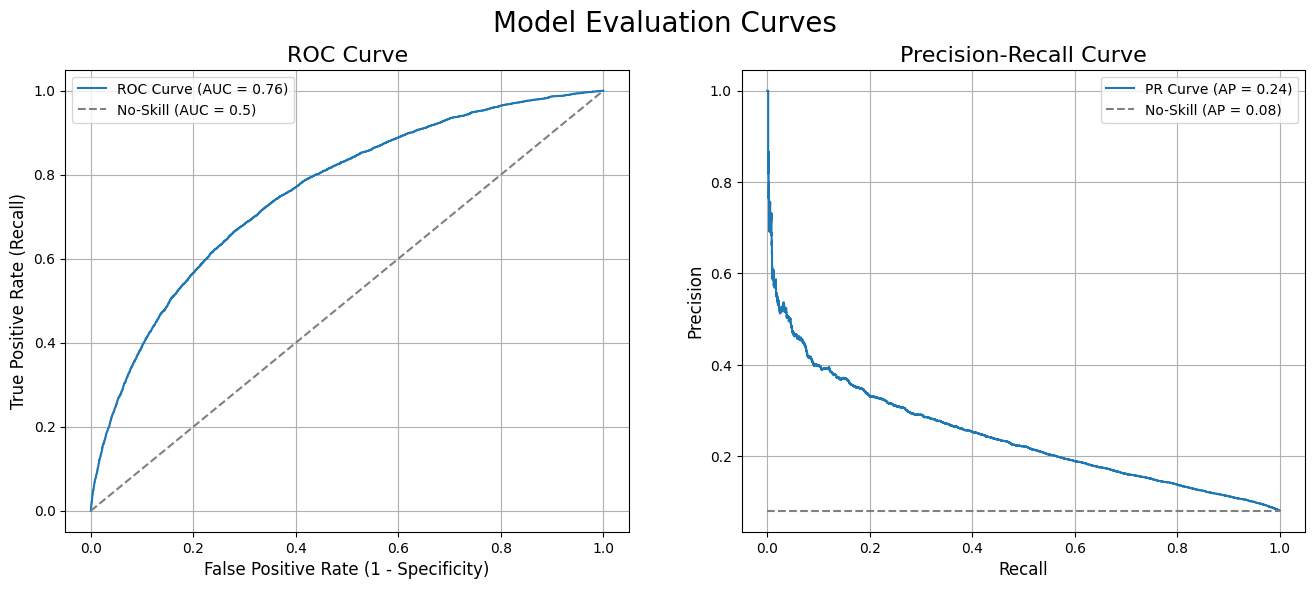

Saved evaluation curves.


In [ ]:
fpr, tpr, _ = roc_curve(y_test, y_test_proba)
roc_auc_value = roc_auc_score(y_test, y_test_proba)

pr_precision, pr_recall, _ = precision_recall_curve(y_test, y_test_proba)
pr_auc_value = auc(pr_recall, pr_precision)

fig_roc, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

ax1.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc_value:.2f})')
ax1.plot([0, 1], [0, 1], linestyle='--', color='gray', label='No-Skill (AUC = 0.5)')
ax1.set_title('ROC Curve', fontsize=16)
ax1.set_xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
ax1.set_ylabel('True Positive Rate (Recall)', fontsize=12)
ax1.legend(); ax1.grid(True)

ax2.plot(pr_recall, pr_precision, label=f'PR Curve (AP = {pr_auc_value:.2f})')
no_skill = (y_test == 1).mean()
ax2.plot([0, 1], [no_skill, no_skill], linestyle='--', color='gray', label=f'No-Skill (AP = {no_skill:.2f})')
ax2.set_title('Precision-Recall Curve', fontsize=16)
ax2.set_xlabel('Recall', fontsize=12)
ax2.set_ylabel('Precision', fontsize=12)
ax2.legend(); ax2.grid(True)

fig_roc.suptitle('Model Evaluation Curves', fontsize=20)
fig_roc.savefig(os.path.join(MODEL_OUTPUT_DIR, 'model_evaluation_curves.png'), dpi=150, bbox_inches='tight')
plt.show()

print("Saved evaluation curves.")

### 7.b Calibration Curves

A calibration curve (or reliability diagram) is a visual tool that checks if your model's predicted probabilities match reality. If a model predicts a 70% chance of a default happening, approximately 70% of those cases should actually happen. How its plotted:
- **X-axis**: The predicted probabilities grouped into "buckets" (e.g., all cases where the model predicted 0.6 to 0.7).
- **Y-axis**: The actual fraction of positive events that occurred in those buckets.
- **Diagonal Line**: The perfect calibration line (often y=x), where predicted probabilities exactly equal observed frequencies. If the model predicts a 20% chance of default, exactly 20% of the people in that bucket actually default.
- **The Colored Line**: This is your actual model. If the line drops below the gray dashed line, your model is over-predicting risk (predicting more defaults than actually happen). If it goes above the gray line, it is under-predicting risk.


However, it is not always perfect. If the data is highly imbalanced or the model does not perfectly fit the data, the calibration curve might bend away from the diagonal line.


> **Uniform binning** divides the probability spectrum into 10 perfectly equal widths: 0-10%, 10-20%, 20-30%, all the way up to 90-100%. Uniform binning then plots a dot for those 3 applicants all the way up at the top right of the chart.

> **Quantile binning** does not care about the 0-100% spectrum. It forces exactly 10% of your total applicant volume into each of the 10 buckets. If you have 10,000 applicants, every single dot on that chart represents exactly 1,000 people. 

In [ ]:
from sklearn.calibration import calibration_curve

# Number of bins to divide the probabilities into
N_BINS = 20

# Calculate Calibration Curves using scikit-learn

# Strategy 1: Uniform (Equal-width probability ranges, e.g., 0-10%, 10-20%)
prob_true_uni, prob_pred_uni = calibration_curve(
    y_test, y_test_proba, n_bins=N_BINS, strategy='uniform'
)

# Strategy 2: Quantile (Equal number of applicants in each bin)
prob_true_quant, prob_pred_quant = calibration_curve(
    y_test, y_test_proba, n_bins=N_BINS, strategy='quantile'
)
# ==============================================================================
# 2. PLOTTING THE CHARTS
# ==============================================================================
fig_cal, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# --- Plot 1: Uniform Binning ---
ax1.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Perfect Calibration')
ax1.plot(prob_pred_uni, prob_true_uni, marker='o', color='#C44E52', 
         linewidth=2, markersize=8, label='Model Predictions')

ax1.set_title('Calibration Curve (Uniform Binning)', fontsize=14, fontweight='bold')
ax1.set_xlabel('Mean Predicted Probability', fontsize=12)
ax1.set_ylabel('Actual Default Rate (Fraction of Positives)', fontsize=12)
ax1.set_xlim([0.0, max(prob_pred_uni)+0.05])
ax1.set_ylim([0.0, max(prob_pred_uni)+0.05])
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(loc='upper left', fontsize=11)

# --- Plot 2: Quantile Binning ---
ax2.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Perfect Calibration')
ax2.plot(prob_pred_quant, prob_true_quant, marker='s', color='#4C72B0', 
         linewidth=2, markersize=8, label='Model Predictions')

ax2.set_title('Calibration Curve (Quantile Binning)', fontsize=14, fontweight='bold')
ax2.set_xlabel('Mean Predicted Probability', fontsize=12)
ax2.set_ylabel('Actual Default Rate (Fraction of Positives)', fontsize=12)
ax2.set_xlim([0.0, max(prob_pred_quant)+0.05])
ax2.set_ylim([0.0, max(prob_pred_quant)+0.05])
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(loc='upper left', fontsize=11)
fig_cal.suptitle('Calibration Curves', fontsize=20)
plt.tight_layout()
plt.show()

fig_cal.savefig(os.path.join(MODEL_OUTPUT_DIR, 'calibration_curves.png'), dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
def ece_from_binned_table(df, volume_col, pred_pd_col, actual_rate_col):
    """
    Calculates Expected Calibration Error (ECE) directly from a binned summary DataFrame.
    
    Parameters:
    -----------
    df : pandas.DataFrame
        The aggregated binned table.
    volume_col : str
        Column name for total applicants/volume in each bin (e.g., 'Total_Applicants').
    pred_pd_col : str
        Column name for the mean predicted probability in each bin (e.g., 'Average_PD').
    actual_rate_col : str
        Column name for the actual default rate in each bin (e.g., 'Actual_Default_Rate').
    """
    # 1. Total number of applicants across the entire portfolio
    total_volume = df[volume_col].sum()
    
    # 2. Calculate the absolute difference between predicted PD and actual default rate for each bin
    abs_bin_error = (df[pred_pd_col] - df[actual_rate_col]).abs()
    
    # 3. Weight each bin's error by its proportion of total portfolio volume
    weighted_bin_error = (df[volume_col] / total_volume) * abs_bin_error
    
    # 4. Sum up the weighted errors to get final ECE
    ece = weighted_bin_error.sum()
    
    return ece

In [ ]:
# ==============================================================================
# 1. QUANTILE BINNING TABLE (Equal Volume - The Industry Standard)
# ==============================================================================

dist_df = pd.DataFrame({
    'Probability': y_test_proba,
    'Actual_Default': y_test.values 
})
# 1. Create Quantile Bins
dist_df['Quantile_Bin'] = pd.qcut(dist_df['Probability'], q=20, duplicates='drop')

quantile_table = dist_df.groupby('Quantile_Bin').agg(
    Total_Applicants=('Probability', 'count'),
    Defaults=('Actual_Default', 'sum'),
    Average_PD=('Probability', 'mean'),
    Actual_Default_Rate=('Actual_Default', 'mean')
).reset_index()
quantile_table['Expected_Defaults'] = (quantile_table['Total_Applicants'] * quantile_table['Average_PD']).round(2)

print("=== QUANTILE BINNING (Equal Volume) ===")
display_table = quantile_table.copy()
# Format as percentages for clean reading
display_table['Average_PD'] = (display_table['Average_PD'] * 100).round(2).astype(str) + '%'
display_table['Actual_Default_Rate'] = (display_table['Actual_Default_Rate'] * 100).round(2).astype(str) + '%'
print(display_table.to_string(index=False))

quantile_table.to_excel(os.path.join(MODEL_OUTPUT_DIR, 'quantile_binning_table.xlsx'), index=False)

print("\n" + "="*50)
ece = ece_from_binned_table(quantile_table, 'Total_Applicants', 'Average_PD', 'Actual_Default_Rate')
print(f"Expected Calibration Error (ECE): {ece:.4f}")
print("\n" + "="*50)

In [ ]:
# ==============================================================================
# 2. UNIFORM BINNING TABLE (Equal Width - The Illusion)
# ==============================================================================
dist_df['Uniform_Bin'] = pd.cut(dist_df['Probability'], bins=np.linspace(0, 1, 21))

uniform_table = dist_df.groupby('Uniform_Bin', observed=False).agg(
    Total_Applicants=('Probability', 'count'),
    Defaults=('Actual_Default', 'sum'),
    Average_PD=('Probability', 'mean'),
    Actual_Default_Rate=('Actual_Default', 'mean')
).reset_index()

# Format as percentages
uniform_table['Average_PD'] = (uniform_table['Average_PD'] * 100).round(2).astype(str) + '%'
uniform_table['Actual_Default_Rate'] = (uniform_table['Actual_Default_Rate'] * 100).round(2).astype(str) + '%'

print("\n\n=== UNIFORM BINNING (Equal Width) ===")
print(uniform_table.to_string(index=False))

uniform_table.to_excel(os.path.join(MODEL_OUTPUT_DIR, 'uniform_binning_table.xlsx'), index=False)

### 7.c Discrimination Test (KS Curve)

In [ ]:
# 2. Sort so that Highest Risk (highest PD) is at the top (Decile 1)
ks_table = quantile_table.copy()
ks_table = ks_table.sort_values(by='Average_PD', ascending=False).reset_index(drop=True)
ks_table.index = ks_table.index + 1  # Make index 1-10 for standard Decile reading
ks_table.index.name = 'Decile'
ks_table.rename(columns={'Defaults': 'Bads'}, inplace=True)  # Rename for KS terminology

# 3. Calculate 'Goods' (Non-Defaulters)
ks_table['Goods'] = ks_table['Total_Applicants'] - ks_table['Bads']

# 4. Calculate % of Total Bads and % of Total Goods per bin
total_bads = ks_table['Bads'].sum()
total_goods = ks_table['Goods'].sum()

ks_table['Pct_Bads'] = ks_table['Bads'] / total_bads
ks_table['Pct_Goods'] = ks_table['Goods'] / total_goods

# 5. Calculate Cumulative Percentages
ks_table['Cum_Pct_Bads'] = ks_table['Pct_Bads'].cumsum()
ks_table['Cum_Pct_Goods'] = ks_table['Pct_Goods'].cumsum()

# 6. Calculate the KS Spread (The difference between Cum Bads and Cum Goods)
ks_table['KS_Spread'] = (ks_table['Cum_Pct_Bads'] - ks_table['Cum_Pct_Goods']) * 100

# 7. Identify the final KS Statistic (The maximum spread)
ks_statistic = ks_table['KS_Spread'].max()
ks_max_decile = ks_table['KS_Spread'].idxmax()

ks_table.to_excel(os.path.join(MODEL_OUTPUT_DIR, 'ks_table.xlsx'), index=True)

In [ ]:
display_table = ks_table.copy()

# Format percentages for clean reading
cols_to_pct = ['Average_PD', 'Pct_Bads', 'Pct_Goods', 'Cum_Pct_Bads', 'Cum_Pct_Goods']
for col in cols_to_pct:
    display_table[col] = (display_table[col] * 100).round(2).astype(str) + '%'

display_table['KS_Spread'] = display_table['KS_Spread'].round(2)

print("--- FULL KS TABLE ---")
print(display_table[['Quantile_Bin', 'Total_Applicants', 'Bads', 'Goods', 
                     'Average_PD', 'Cum_Pct_Bads', 'Cum_Pct_Goods', 'KS_Spread']].to_string())

print("\n" + "="*50)
print(f"✅ FINAL KS STATISTIC: {ks_statistic:.2f} (Captured in Decile {ks_max_decile})")
print("="*50)

In [ ]:
# ==============================================================================
# 4. PLOTTING THE KS CURVE
# ==============================================================================

# Extract the data from the ks_table we built in the previous step
deciles = ks_table.index.values
cum_bads = ks_table['Cum_Pct_Bads'] * 100
cum_goods = ks_table['Cum_Pct_Goods'] * 100
ks_spread = ks_table['KS_Spread']

# Find the decile where the KS statistic (maximum spread) occurs
ks_max_decile = ks_spread.idxmax()
ks_max_bad = cum_bads[ks_max_decile]
ks_max_good = cum_goods[ks_max_decile]
ks_stat_value = ks_spread[ks_max_decile]

# Create the plot
fig_ks, ax = plt.subplots(figsize=(10, 6))

# Plot the cumulative curves
ax.plot(deciles, cum_bads, marker='o', color='#C44E52', linewidth=2.5, markersize=8, label='Cumulative % Bads (Defaulters)')
ax.plot(deciles, cum_goods, marker='s', color='#4C72B0', linewidth=2.5, markersize=8, label='Cumulative % Goods (Non-Defaulters)')

# Draw a vertical dashed line to highlight the KS gap
ax.vlines(x=ks_max_decile, ymin=ks_max_good, ymax=ks_max_bad, color='black', 
          linestyle='--', linewidth=2, zorder=3)

# Add an annotation pointing to the KS gap
ax.annotate(f'KS Statistic: {ks_stat_value:.2f}\n(Max Spread at Decile {ks_max_decile})', 
            xy=(ks_max_decile, (ks_max_bad + ks_max_good) / 2), 
            xytext=(ks_max_decile + 0.5, (ks_max_bad + ks_max_good) / 2),
            arrowprops=dict(facecolor='black', shrink=0.05, width=1.5, headwidth=8),
            fontsize=11, fontweight='bold', 
            bbox=dict(boxstyle="round,pad=0.4", fc="white", ec="black", lw=1.5))

# Formatting the chart
ax.set_title('Kolmogorov-Smirnov (KS) Curve', fontsize=16, fontweight='bold')
ax.set_xlabel('Risk Decile (1 = Highest Risk, 20 = Lowest Risk)', fontsize=12)
ax.set_ylabel('Cumulative Percentage (%)', fontsize=12)

# Ensure X-axis only shows whole numbers 1 through 20
ax.set_xticks(deciles)
# Ensure Y-axis goes from 0 to 100 with steps of 10
ax.set_yticks(np.arange(0, 110, 10))

ax.grid(True, linestyle='--', alpha=0.6)
ax.legend(loc='lower right', fontsize=12)

plt.tight_layout()
fig_ks.savefig(os.path.join(MODEL_OUTPUT_DIR, 'KS_Curve.png'), dpi=150, bbox_inches='tight')
plt.show()

### 7.d Data Drift - test vs train (PSI test)

In [ ]:
def calculate_psi(grp1, grp2, n_bins=10, min_bin_edge = 0, max_bin_edge = 1):
    """
    Calculates the Population Stability Index (PSI) between training (expected)
    and validation/production (actual) predicted probabilities.
    """
    # 1. Determine quantile bin edges using the grp1 dataset
    _, bin_edges = pd.qcut(grp1, n_bins, retbins=True)
    
    # Adjust outer edges slightly to prevent out-of-bounds errors
    bin_edges[0] = min_bin_edge
    bin_edges[-1] = max_bin_edge
    
    # 2. Count how many applicants fall into each bin for both datasets
    grp1_counts = np.histogram(grp1, bins=bin_edges)[0]
    grp2_counts = np.histogram(grp2, bins=bin_edges)[0]
    
    # 3. Convert counts to percentages
    grp1_pct = grp1_counts / len(grp1)
    grp2_pct = grp2_counts / len(grp2)
    
    # 4. Handle any zero-count bins to avoid division-by-zero/log errors
    grp1_pct = np.where(grp1_pct == 0, 1e-4, grp1_pct)
    grp2_pct = np.where(grp2_pct == 0, 1e-4, grp2_pct)
    
    # 5. Calculate PSI for each bin and sum them up
    # Formula: (Actual% - Expected%) * ln(Actual% / Expected%)
    bin_psi = (grp2_pct - grp1_pct) * np.log(grp2_pct / grp1_pct)
    total_psi = np.sum(bin_psi)

    psi_df = pd.DataFrame({
        'Bin': [f'Bin {i+1}' for i in range(n_bins)],
        'Bin_Range': [f"{bin_edges[i]:.4f} - {bin_edges[i+1]:.4f}" for i in range(n_bins)],
        'Expected_Pct': grp1_pct,
        'Actual_Pct': grp2_pct,
        'PSI_Contribution': bin_psi
    })

    return total_psi, psi_df

# --- Example Usage ---
# psi_value = calculate_psi(y_train_proba, y_test_proba, n_bins=10)
# print(f"Population Stability Index (PSI): {psi_value:.4f}")

In [ ]:
psi_value, psi_df = calculate_psi(train_df.predicted_proba, test_df.predicted_proba, n_bins=10, min_bin_edge=0, max_bin_edge=1)
psi_df.to_excel(os.path.join(MODEL_OUTPUT_DIR, 'psi_table.xlsx'), index=False)

print("="*40)
print(f"Train vs. Test PSI: {psi_value:.4f}")
print("="*40)

if psi_value < 0.10:
    print("🟢 PASS: The test population is highly stable and representative of the training data.")
elif psi_value < 0.25:
    print("🟡 WARNING: Moderate shift detected. Check your data split for potential bias.")
else:
    print("🔴 FAIL: Significant distribution shift! Your validation set is fundamentally different from your training set.")

## 8. MLflow Tracking & Model Registration

Logs hyperparameters, metrics, plots, and a production-ready `pyfunc` wrapper that
handles categorical dtype reconstruction at inference time.

In [ ]:
import subprocess, sys
from urllib.parse import urlparse

# Manual local runs only: start the MLflow server in the background. Under Airflow/Docker the
# tracking URI is http://mlflow:5000 (the mlflow container), so nothing is started there.
mlflow_server = None
if ENABLE_MLFLOW and urlparse(MLFLOW_TRACKING_URI).hostname in ("localhost", "127.0.0.1"):
    mlflow_server = subprocess.Popen([sys.executable, os.path.join(PROJECT_ROOT, "scripts", "start_mlflow_server.py")],
                     stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)

In [40]:
if ENABLE_MLFLOW:
    import mlflow
    import mlflow.pyfunc
    from mlflow.models import infer_signature
    from mlflow.tracking import MlflowClient

    mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)
    mlflow.set_experiment(MLFLOW_EXPERIMENT_NAME)

    input_example  = X_test.head(3)
    output_example = final_model.predict(input_example)
    model_signature = infer_signature(input_example, output_example)

    print(f"MLflow tracking URI : {MLFLOW_TRACKING_URI}")
    print(f"MLflow experiment   : {MLFLOW_EXPERIMENT_NAME}")
else:
    print("ENABLE_MLFLOW=False — skipping MLflow tracking section.")

ENABLE_MLFLOW=False — skipping MLflow tracking section.


In [41]:
if ENABLE_MLFLOW:

    class LightGBMProductionWrapper(mlflow.pyfunc.PythonModel):
        """
        Wraps the trained LightGBM model so the MLflow pyfunc API can serve it.
        Reconstructs pandas 'category' dtype for categorical columns, since this
        information is lost when the model is served over JSON.
        """
        def __init__(self, trained_model, categorical_features):
            self.trained_model = trained_model
            self.categorical_features = categorical_features

        def predict(self, context, model_input):
            processed_df = model_input.copy()
            for col in self.categorical_features:
                if col in processed_df.columns:
                    processed_df[col] = processed_df[col].astype('category')
            probabilities = self.trained_model.predict_proba(processed_df)
            return probabilities[:, 1].tolist()

    cat_features = [col for col in X_test.columns if X_test[col].dtype.name == 'category']
    wrapped_production_model = LightGBMProductionWrapper(
        trained_model=final_model,
        categorical_features=cat_features,
    )
    print(f"Wrapped model with {len(cat_features)} categorical features.")

In [ ]:
if ENABLE_MLFLOW:

    with mlflow.start_run(run_name=MLFLOW_RUN_NAME) as run:
        mlflow.set_tag("model_name", MLFLOW_RUN_NAME)
        mlflow.set_tag("hyperparameters_source", HYPERPARAMS_SOURCE)
        mlflow.log_params(resolved_best)
        mlflow.log_param("device", "cpu")
        mlflow.log_param("random_state", RANDOM_STATE)
        mlflow.log_param("test_size", TEST_SIZE)
        mlflow.log_param("cv_folds", CV_FOLDS)
        mlflow.log_param("n_estimators_max", N_ESTIMATORS_MAX)

        # Same hyperparameters as the log_params()/log_param() calls above, also
        # saved as a single downloadable JSON artifact -- useful for diffing
        # against another run's file, or reloading exactly as-is outside MLflow.
        hyperparameters_used = {
            **resolved_best,
            "device": "cpu",
            "random_state": RANDOM_STATE,
            "test_size": TEST_SIZE,
            "cv_folds": CV_FOLDS,
        }
        mlflow.log_dict(hyperparameters_used, "metadata/hyperparameters.json")
        mlflow.log_dict(feature_list, "metadata/selected_features.json")   # features + rule from tuning

        mlflow.log_metric("best_iteration", BEST_ITER)
        mlflow.log_metric("train_auc", train_auc)
        mlflow.log_metric("train_gini", train_gini)
        # Training-set metrics at the CV-chosen threshold -- compare with the
        # test_* metrics to gauge overfitting
        y_train_pred = (y_train_proba >= best_threshold).astype(int)
        mlflow.log_metric("train_accuracy",         accuracy_score(y_train, y_train_pred))
        mlflow.log_metric("train_precision_class1", precision_score(y_train, y_train_pred))
        mlflow.log_metric("train_recall_class1",    recall_score(y_train, y_train_pred))
        mlflow.log_metric("train_f1_score",         f1_score(y_train, y_train_pred))
        # Cross-validation on the training set: chooses the number of trees and the threshold
        mlflow.log_metric("cv_auc_mean", cv_auc_mean)
        mlflow.log_metric("cv_auc_std", cv_auc_std)
        mlflow.log_metric("oof_auc", oof_auc)
        mlflow.log_metric("oof_accuracy", accuracy_score(y_train, y_oof_pred))
        mlflow.log_metric("oof_f1_score", best_f1_score)
        mlflow.log_metric("threshold", best_threshold)
        # Untouched holdout: the model's reported performance. Class '1' (default)
        # is the metric of interest
        mlflow.log_metric("test_auc", test_auc)
        mlflow.log_metric("test_auc_ci_low", test_auc_ci_low)
        mlflow.log_metric("test_auc_ci_high", test_auc_ci_high)
        mlflow.log_metric("test_gini", test_gini)
        mlflow.log_metric("test_log_loss", log_loss(y_test, y_test_proba))
        mlflow.log_metric("test_accuracy", accuracy_score(y_test, y_test_pred))
        mlflow.log_metric("test_precision_class1", report_df.loc['1', 'precision'])
        mlflow.log_metric("test_recall_class1",    report_df.loc['1', 'recall'])
        mlflow.log_metric("test_f1_score",         report_df.loc['1', 'f1-score'])
        mlflow.log_metric("ks_statistic", ks_statistic)
        mlflow.log_metric("Calibration_Error", ece)

        mlflow.pyfunc.log_model(
            name="lightgbm_model",
            python_model=wrapped_production_model,
            registered_model_name=MLFLOW_REGISTERED_MODEL_NAME,
            signature=model_signature,
            # Category columns as plain text, matching the signature (which stores them as strings)
            input_example=input_example.astype({c: "object" for c in cat_features}),
        )
        mlflow.log_figure(figure=fig_roc, artifact_file="plots/ModelEvaluationCurves.png", save_kwargs=dict(dpi=150, bbox_inches='tight'))
        mlflow.log_figure(figure=fig_cal, artifact_file="plots/CalibrationCurves.png", save_kwargs=dict(dpi=150, bbox_inches='tight'))
        mlflow.log_figure(figure=fig_ks, artifact_file="plots/KS_Curve.png", save_kwargs=dict(dpi=150, bbox_inches='tight'))
        mlflow.log_figure(figure=fig_shap_summary, artifact_file="plots/SHAP_Summary.png", save_kwargs=dict(dpi=150, bbox_inches='tight'))
        mlflow.log_figure(figure=fig_shap_waterfall, artifact_file="plots/SHAP_Waterfall_Example.png", save_kwargs=dict(dpi=150, bbox_inches='tight'))
        mlflow.log_figure(figure=fig_pdp, artifact_file="plots/PartialDependence.png", save_kwargs=dict(dpi=150, bbox_inches='tight'))
        mlflow.log_text(text=report_text, artifact_file="metadata/classification_report.txt")
        mlflow.log_artifact(
            local_path=os.path.join(MODEL_OUTPUT_DIR, 'lgbm_feature_importance.xlsx'),
            artifact_path="metadata",
        )
        mlflow.log_artifact(
            local_path=os.path.join(MODEL_OUTPUT_DIR, 'shap_feature_importance.xlsx'),
            artifact_path="metadata",
        )
        mlflow.log_artifact(
            local_path=os.path.join(MODEL_OUTPUT_DIR, 'quantile_binning_table.xlsx'),
            artifact_path="metadata",
        )
        mlflow.log_artifact(
            local_path=os.path.join(MODEL_OUTPUT_DIR, 'uniform_binning_table.xlsx'),
            artifact_path="metadata",
        )
        mlflow.log_artifact(
            local_path=os.path.join(MODEL_OUTPUT_DIR, 'ks_table.xlsx'),
            artifact_path="metadata",
        )

        mlflow.log_artifact(
            local_path=os.path.join(MODEL_OUTPUT_DIR, 'shap_values_sample.parquet'),
            artifact_path="metadata",
        )
        mlflow.log_metric("shap_max_additivity_error", max_additivity_error)
        mlflow.log_artifact(
            local_path=os.path.join(MODEL_OUTPUT_DIR, 'feature_importance_combined.xlsx'),
            artifact_path="metadata",
        )
        print(f"Success! Run ID: {run.info.run_id}")

In [43]:
if ENABLE_MLFLOW:

    # FIX: client instantiated BEFORE use (original called it one cell too early)
    client = MlflowClient(tracking_uri=MLFLOW_TRACKING_URI)

    latest_versions = client.get_latest_versions(name=MLFLOW_REGISTERED_MODEL_NAME)
    newest_version = max(latest_versions, key=lambda v: int(v.version))

    # client.set_registered_model_alias(
    #     name=MLFLOW_REGISTERED_MODEL_NAME,
    #     alias="prod",
    #     version=newest_version.version,
    # )

    # Promotion to prod is a manual, deliberate gate — assign the alias yourself
    # in the MLflow UI (Models -> HomeCredit_Scorecard_Model -> select a version
    # -> Add alias -> 'prod') after reviewing this run's metrics.
    print(f"Registered model version: {newest_version.version}")
    print(f"Run ID for this version : {newest_version.run_id}")
    print("\n'prod' alias not set automatically — assign it manually in the MLflow UI "
          "once you've reviewed this run.")

### Viewing the MLflow UI

The UI is served by the same tracking server this notebook logs to. Start it from
a terminal in the project root (if it isn't already running), then open
http://localhost:5000.

On Windows, without Docker (keep the terminal open):

```bash
python scripts/start_mlflow_server.py
```

Or with Docker:

```bash
docker compose up -d mlflow
```

When this notebook runs locally, the cell at the start of Section 8 starts the
server automatically (if it isn't already running) and the cell at the end of the
section stops it again. Under Airflow/Docker the `mlflow` container is the server,
so both cells do nothing there.

**Stop the mlflow Server**

In [ ]:
import psutil

# Stop the server this notebook started: the start script plus everything it launched
# (mlflow server and its worker processes -- Windows doesn't stop children with the parent)
if mlflow_server is not None and mlflow_server.poll() is None:
    parent = psutil.Process(mlflow_server.pid)
    procs = [parent] + parent.children(recursive=True)
    for p in procs:
        try:
            p.terminate()
        except psutil.NoSuchProcess:
            pass
    gone, alive = psutil.wait_procs(procs, timeout=10)
    for p in alive:
        p.kill()
    print(f"Stopped MLflow server ({len(procs)} process(es)).")

## 9. Cleanup

In [44]:
del X_train, X_test, y_train, y_test, X, y, model_dataset, fold_models
import gc; gc.collect()
print("All DataFrames released.")

All DataFrames released.
